# Zadanie 3 Extra — DeepWeeds: wiarygodność ewaluacji

**Pytanie badawcze:** czy wynik modelu na opublikowanym podziale DeepWeeds odzwierciedla rozpoznawanie gatunków chwastów, czy może jest częściowo zawyżony przez bardzo podobne ujęcia obecne w zbiorach treningowym i testowym?

Twoim celem nie jest pobicie modelu bazowego. Masz zaprojektować i przeprowadzić badanie, które pozwoli ocenić wiarygodność jego ewaluacji. Równie wartościowy jest wynik potwierdzający hipotezę, jak i poprawnie uzasadniony wynik, który jej nie potwierdza.

In [1]:
# Importy i ustawienia
import json
import platform
import sys
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torchvision
from huggingface_hub import hf_hub_download, snapshot_download
from PIL import Image
from safetensors.torch import load_file
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

RS = 42                                    # ziarno losowości
np.random.seed(RS)
torch.manual_seed(RS)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [ ]:
DATA_DIR = Path("data/zadanie-3")
MODEL_DIR = Path("models/zadanie-3-model-bazowy")
DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

images_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-3",
    filename="original/images.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
dataset_snapshot = snapshot_download(
    repo_id="AI-MED-AGH/Recruitment-Task-3",
    repo_type="dataset",
    allow_patterns=["labels/*.csv"],
    local_dir=DATA_DIR,
)
model_snapshot = snapshot_download(
    repo_id="AI-MED-AGH/Recruitment-Task-3-Model",
    local_dir=MODEL_DIR,
)
with ZipFile(images_path) as archive:
    archive.extractall(DATA_DIR / "images")

print(f"Dane: {dataset_snapshot}")
print(f"Model bazowy: {model_snapshot}")

Dane: C:\Users\papie\Rekrutacja-AI-Med-2026-2027\Zadanie-3\data\zadanie-3
Model bazowy: C:\Users\papie\Rekrutacja-AI-Med-2026-2027\Zadanie-3\models\zadanie-3-model-bazowy


## Najważniejsze zasady

- Korzystaj z opublikowanego **foldu 0**: `train_subset0.csv`, `val_subset0.csv` i `test_subset0.csv`. We wszystkich porównaniach zachowaj ten sam zbiór testowy.
- Sposób mierzenia podobieństwa i jego próg ustal na danych treningowych i walidacyjnych, zanim przeanalizujesz wyniki testowe.
- Główną metryką jest **macro-F1**. Pokaż również wyniki dla poszczególnych klas.
- We wszystkich wariantach użyj tego samego modelu, preprocessingu i procedury treningowej.
- Zadbaj o odtwarzalność: zapisz najważniejsze ustawienia, ziarno losowe i wersje bibliotek.

## A — Hipoteza i plan badania

Przeczytaj oryginalną publikację DeepWeeds oraz co najmniej jedno dodatkowe źródło dotyczące duplikatów lub zależnych obserwacji w ewaluacji modeli. Krótko wyjaśnij, dlaczego podobne ujęcia w treningu i teście mogą zawyżać wynik.

Zapisz jedną hipotezę: usunięcie z treningu obrazów bardzo podobnych do testowych obniży wynik bardziej niż usunięcie takiej samej liczby losowych obrazów. Przed eksperymentem określ, jak duża różnica będzie dla Ciebie istotna praktycznie.

Uruchom dostarczony checkpoint, aby sprawdzić wczytywanie danych i inferencję. Jest to celowo słaby model techniczny. Do właściwego eksperymentu wybierz jeden rozsądny model na podstawie zbiorów treningowego i walidacyjnego.

### Dlaczego podobne ujęcia mogą zawyżać wynik
DeepWeeds (Olsen i in., 2019) to 17 509 zdjęć z ośmiu miejsc w północnej Australii, robionych
kamerą na specjalnym przyrządzie podczas przejść przez teren. Autorzy podzielili zbiór
**losowo** (warstwowo według klas) na 60% treningu, 20% walidacji i 20% testu. Zdjęcia z jednego
przejścia, zrobione w odstępie kilku sekund, pokazują często tę samą roślinę z niemal tego samego
miejsca. Przy losowym podziale takie prawie identyczne ujęcia trafiają jednocześnie do treningu
i do testu. Model może wtedy poprawnie rozpoznać zdjęcie testowe dlatego, że widział jego
"bliźniaka", a nie dlatego, że nauczył się cech gatunku. Wynik testu mierzy wtedy częściowo
pamięć, a nie uogólnianie. Barz i Denzler (2020) pokazali to na CIFAR: 3,3% obrazów testowych
CIFAR-10 i 10% CIFAR-100 miało prawie duplikaty w treningu, a po ich wymianie błąd modeli
wzrósł (średnio o 0,41 i 2,73 punktu procentowego).

### Hipoteza
Usunięcie z treningu obrazów bardzo podobnych do testowych obniży macro F1 na teście bardziej
niż usunięcie takiej samej liczby losowych obrazów (z zachowaniem liczebności klas).

### Kryterium ustalone przed eksperymentem
Miara efektu: **Δ = macro F1 (kontrolny) minus macro F1 (oczyszczony)**, oba na tym samym teście.
- Uznaję hipotezę za potwierdzoną, jeśli **Δ ≥ 0,02** (2 punkty procentowe macro F1)
  **i** dolna granica 95% przedziału ufności dla Δ (bootstrap) jest większa od zera.
- Δ poniżej 0,02 uznaję za praktycznie nieistotne, nawet jeśli jest statystycznie różne od zera.
Uzasadnienie progu: 2 punkty procentowe to więcej niż typowe różnice między popularnymi
architekturami na tym zbiorze, a mniej niż różnica między słabym i dobrym modelem.

### Plan
1. Sprawdzić dostarczony checkpoint (wczytywanie danych i inferencja).
2. Wybrać jeden model na danych treningowych i walidacyjnych.
3. Zmierzyć podobieństwo zdjęć i ustalić próg tylko na treningu i walidacji.
4. Policzyć, ile zdjęć testowych ma bliźniaka w treningu, i zbudować trzy warianty treningu.
5. Wytrenować ten sam model na każdym wariancie i porównać wyniki z oceną niepewności.

In [2]:
# A1. Ustawienia i wersje bibliotek (odtwarzalność)
DATA_DIR = Path("data/zadanie-3")                 # te same ścieżki co w komórce pobierania
MODEL_DIR = Path("models/zadanie-3-model-bazowy")
USTAWIENIA = {
    "fold": 0,
    "ziarno": RS,
    "siec do cech": "ResNet34, wagi ImageNet (timm, resnet34-43635321.pth), bez douczania",
    "wejscie": "RGB, 224 x 224, normalizacja ImageNet",
    "klasyfikator": "regresja logistyczna na standaryzowanych cechach",
    "podobienstwo": "cosinus między cechami ResNet34",
    "metryka glowna": "macro F1",
}
for klucz, wartosc in USTAWIENIA.items():
    print(f"{klucz:15s} {wartosc}")
print()
print("Python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

fold            0
ziarno          42
siec do cech    ResNet34, wagi ImageNet (timm, resnet34-43635321.pth), bez douczania
wejscie         RGB, 224 x 224, normalizacja ImageNet
klasyfikator    regresja logistyczna na standaryzowanych cechach
podobienstwo    cosinus między cechami ResNet34
metryka glowna  macro F1

Python 3.13.16 | torch 2.14.0+cu130 | torchvision 0.29.0+cu130 | scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


In [3]:
# A2. Fold 0: podziały i klasy
LABELS = DATA_DIR / "labels"
IMG_DIR = DATA_DIR / "images"
train = pd.read_csv(LABELS / "train_subset0.csv")
val = pd.read_csv(LABELS / "val_subset0.csv")
test = pd.read_csv(LABELS / "test_subset0.csv")

# Nazwy klas biorę z labels.csv (kolumna Species), bo to jedyne źródło przypisania numer -> gatunek.
gatunki = pd.read_csv(LABELS / "labels.csv")
KLASY = gatunki.groupby("Label")["Species"].agg(lambda s: s.mode()[0]).tolist()
print("klasy:", KLASY)

liczebnosc = pd.DataFrame({
    "train": train["Label"].value_counts().sort_index(),
    "val": val["Label"].value_counts().sort_index(),
    "test": test["Label"].value_counts().sort_index(),
})
liczebnosc.index = KLASY
print(liczebnosc)
print("wspólne pliki train/val/test:",
      len(set(train.Filename) & set(test.Filename)), len(set(val.Filename) & set(test.Filename)),
      len(set(train.Filename) & set(val.Filename)))

# Uwaga: config.json modelu bazowego podaje nazwy klas alfabetycznie, co nie zgadza się z labels.csv.
nazwy_w_config = json.load(open(MODEL_DIR / "config.json"))["class_names"]
print("\nconfig.json modelu bazowego:", nazwy_w_config)
print("klasy niezgodne z labels.csv:",
      [(i, a, b) for i, (a, b) in enumerate(zip(nazwy_w_config, KLASY)) if a != b])

klasy: ['Chinee apple', 'Lantana', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed', 'Negative']
                train   val  test
Chinee apple      675   225   226
Lantana           637   213   213
Parkinsonia       618   206   207
Parthenium        613   204   205
Prickly acacia    637   212   213
Rubber vine       605   202   202
Siam weed         644   215   215
Snake weed        609   203   204
Negative         5463  1821  1822
wspólne pliki train/val/test: 0 0 0

config.json modelu bazowego: ['Chinee apple', 'Lantana', 'Negative', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed']
klasy niezgodne z labels.csv: [(2, 'Negative', 'Parkinsonia'), (3, 'Parkinsonia', 'Parthenium'), (4, 'Parthenium', 'Prickly acacia'), (5, 'Prickly acacia', 'Rubber vine'), (6, 'Rubber vine', 'Siam weed'), (7, 'Siam weed', 'Snake weed'), (8, 'Snake weed', 'Negative')]


In [4]:
# A3. Uruchomienie dostarczonego checkpointu (sprawdzenie danych i inferencji)
# Model i jego (celowo błędny) preprocessing pochodzą z repozytorium modelu bazowego.
sys.path.insert(0, str(MODEL_DIR))
from data import build_comparison_transforms   # noqa: E402  (plik data.py modelu bazowego)
from model import SmallDeepWeedsCNN             # noqa: E402

model_bazowy = SmallDeepWeedsCNN(num_classes=9, in_channels=1)
model_bazowy.load_state_dict(load_file(str(MODEL_DIR / "model.safetensors"), device="cpu"), strict=True)
model_bazowy.eval()
transform_bazowy = build_comparison_transforms()["bad_test"]

pred_bazowy = []
with torch.inference_mode():
    for i in range(0, len(test), 128):
        paczka = torch.stack([transform_bazowy(Image.open(IMG_DIR / f)) for f in test.Filename[i:i + 128]])
        pred_bazowy.append(model_bazowy(paczka).argmax(dim=1).numpy())
pred_bazowy = np.concatenate(pred_bazowy)
print(f"model bazowy na teście: macro F1 = {f1_score(test.Label, pred_bazowy, average='macro'):.4f}, "
      f"accuracy = {accuracy_score(test.Label, pred_bazowy):.4f}, "
      f"przewiduje klasę Negative w {np.mean(pred_bazowy == 8):.0%} przypadków")

model bazowy na teście: macro F1 = 0.2066, accuracy = 0.5421, przewiduje klasę Negative w 84% przypadków


### Wnioski z części A
- **Fold 0:** train 10 501, walidacja 3 501, test 3 507 zdjęć, bez wspólnych plików. W każdym
  podziale klasa Negative (brak chwastu) to około 52% zdjęć, każdy z 8 gatunków po około 6%.
- **Checkpoint:** model bazowy dał na teście dokładnie opublikowany wynik (macro F1 0,2066,
  accuracy 0,5421) i w 84% przypadków odpowiada klasą Negative. Wczytywanie danych i inferencja
  działają więc poprawnie.
- **Znalezione niezgodności:** config.json modelu bazowego podaje nazwy klas alfabetycznie,
  przez co od numeru 2 nie zgadzają się z labels.csv (na przykład 2 to Parkinsonia, a nie Negative).
  Nazwy klas biorę z labels.csv. Jedno zdjęcie (20170714-110407-3.jpg) ma w labels.csv inną
  etykietę niż w pliku foldu 0; używam etykiet z plików foldu, jak model bazowy.
- **Wybór modelu:** zamrożona sieć ResNet34 (wagi ImageNet) jako ekstraktor cech i regresja
  logistyczna na tych cechach. Trzeba wytrenować model kilkanaście razy (3 warianty, w tym
  10 losowań kontrolnych), a pełny trening sieci na CPU byłby zbyt kosztowny; polecenie dopuszcza
  zamrożone cechy. Na walidacji najlepsze było C = 0,01 bez wag klas (macro F1 0,705).
  Ten sam model i ta sama procedura są użyte we wszystkich wariantach.

## B — Eksperyment

Wybierz i uzasadnij jeden sposób wykrywania podobnych obrazów, na przykład perceptual hash albo odległość embeddingów. Ustal próg na danych treningowych i walidacyjnych, a następnie ręcznie sprawdź przykładowe pary uznane za podobne i niepodobne.

Sprawdź, ile obrazów testowych ma bardzo podobny odpowiednik w zbiorze treningowym i jak zjawisko rozkłada się między klasami. Następnie przygotuj trzy warianty zbioru treningowego:

1. **oryginalny** — pełny trening z foldu 0;
2. **oczyszczony** — bez obrazów treningowych podobnych do testowych;
3. **kontrolny** — bez takiej samej liczby losowych obrazów, z zachowaniem podobnych liczebności klas.

Wytrenuj ten sam model w każdym wariancie i oceń wszystkie wersje na niezmienionym zbiorze testowym. Jeżeli pełny trening jest zbyt kosztowny, możesz użyć lekkiego modelu albo zamrożonych cech — jednakowo we wszystkich trzech wariantach.

In [5]:
# B1. Cechy obrazów z wstępnie wytrenowanej sieci ResNet34
# Zamiast trenować sieć od zera (kosztowne trzy razy), używam zamrożonej sieci ResNet34 nauczonej
# na ImageNet. Każde zdjęcie zamieniam na wektor 512 liczb (wyjście przed ostatnią warstwą).
# Te same cechy służą do klasyfikacji i do mierzenia podobieństwa zdjęć.
# Wynik zapisuję do pliku, żeby przy kolejnym uruchomieniu nie liczyć go od nowa (około 30 minut na CPU).
PLIK_CECH = DATA_DIR / "cechy_resnet34.npz"
URL_WAG = "https://github.com/huggingface/pytorch-image-models/releases/download/v0.1-weights/resnet34-43635321.pth"

if not PLIK_CECH.exists():
    siec = torchvision.models.resnet34()
    siec.load_state_dict(torch.hub.load_state_dict_from_url(URL_WAG, model_dir=str(DATA_DIR / "wagi"),
                                                            map_location="cpu", check_hash=True))
    siec.fc = nn.Identity()            # usuwamy ostatnią warstwę, zostaje wektor 512 cech
    siec.eval()
    transform_cech = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),   # średnie ImageNet
    ])

    class Zdjecia(Dataset):
        def __init__(self, nazwy):
            self.nazwy = list(nazwy)

        def __len__(self):
            return len(self.nazwy)

        def __getitem__(self, i):
            with Image.open(IMG_DIR / self.nazwy[i]) as obraz:
                return transform_cech(obraz.convert("RGB"))

    wszystkie = sorted(gatunki["Filename"])
    paczki = []
    with torch.inference_mode():
        for paczka in DataLoader(Zdjecia(wszystkie), batch_size=64, num_workers=0):
            paczki.append(siec(paczka).numpy())
    np.savez_compressed(PLIK_CECH, nazwy=np.array(wszystkie), cechy=np.concatenate(paczki).astype(np.float32))

zapis = np.load(PLIK_CECH)
indeks = {nazwa: i for i, nazwa in enumerate(zapis["nazwy"])}
CECHY = zapis["cechy"]


def cechy_dla(df):
    return CECHY[[indeks[f] for f in df.Filename]]


X_train, X_val, X_test = cechy_dla(train), cechy_dla(val), cechy_dla(test)
y_train, y_val, y_test = train.Label.to_numpy(), val.Label.to_numpy(), test.Label.to_numpy()
print("cechy:", X_train.shape, X_val.shape, X_test.shape)

cechy: (10501, 512) (3501, 512) (3507, 512)


In [6]:
# B2. Wybór modelu na treningu i walidacji
# Model: standaryzacja cech + regresja logistyczna. Sprawdzam siłę regularyzacji C oraz wagi klas.
# Wybieram ustawienie z najwyższym macro F1 na walidacji. Test nie bierze w tym udziału.
wyniki_val = []
for C in [0.01, 0.1, 1.0]:
    for wagi in [None, "balanced"]:
        model = make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight=wagi, max_iter=3000))
        model.fit(X_train, y_train)
        wyniki_val.append({"C": C, "wagi klas": str(wagi),
                           "macro F1 val": f1_score(y_val, model.predict(X_val), average="macro")})
wyniki_val = pd.DataFrame(wyniki_val).sort_values("macro F1 val", ascending=False)
print(wyniki_val.round(4).to_string(index=False))
NAJ = wyniki_val.iloc[0]
NAJ_C = float(NAJ["C"])
NAJ_WAGI = None if NAJ["wagi klas"] == "None" else NAJ["wagi klas"]
print(f"\nwybrany model: C = {NAJ_C}, wagi klas = {NAJ_WAGI}")


def nowy_model():
    """Ten sam model i ta sama procedura we wszystkich wariantach."""
    return make_pipeline(StandardScaler(), LogisticRegression(C=NAJ_C, class_weight=NAJ_WAGI, max_iter=3000))

   C wagi klas  macro F1 val
0.01      None        0.7047
0.10      None        0.7011
1.00      None        0.6643
0.10  balanced        0.6640
0.01  balanced        0.6554
1.00  balanced        0.6375

wybrany model: C = 0.01, wagi klas = None


próg podobieństwa (ustalony na train i val): 0.9448
zdjęcia walidacyjne z bliźniakiem w treningu: 98 z 3501 (2.8%)
z nich zrobione w odstępie do 10 minut od bliźniaka: 49.0%
wśród par poniżej progu w odstępie do 10 minut: 25.7%


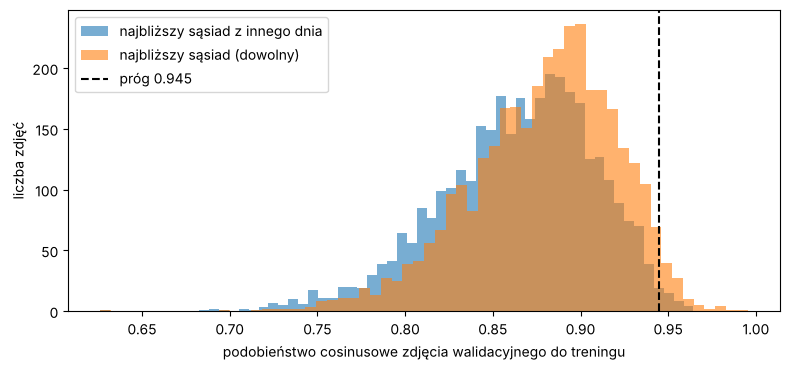

In [7]:
# B3. Podobieństwo zdjęć: cosinus między cechami
# Cosinus to iloczyn skalarny wektorów o długości 1: 1 oznacza identyczny "kierunek" cech,
# 0 brak związku. Tę samą metodę zastosowali Barz i Denzler (2020) do szukania prawie duplikatów.
def normuj(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)


N_train, N_val, N_test = normuj(X_train), normuj(X_val), normuj(X_test)


def czas_zdjecia(df):
    # Nazwa pliku to data i godzina wykonania zdjęcia, na przykład 20170714-142019-3.jpg
    return pd.to_datetime(df.Filename.str[:15], format="%Y%m%d-%H%M%S")


czas_train, czas_val, czas_test = czas_zdjecia(train), czas_zdjecia(val), czas_zdjecia(test)
dzien_train = czas_train.dt.date.to_numpy()

# Dla każdego zdjęcia walidacyjnego: najbardziej podobne zdjęcie treningowe (najbliższy sąsiad).
podob_val = N_val @ N_train.T                     # macierz cosinusów 3501 x 10501
najblizszy = podob_val.argmax(axis=1)
max_val = podob_val.max(axis=1)

# Rozkład "na pewno inne ujęcie": najbliższy sąsiad wśród zdjęć z INNEGO dnia.
inny_dzien = czas_val.dt.date.to_numpy()[:, None] != dzien_train[None, :]
max_inny_dzien = np.where(inny_dzien, podob_val, -1).max(axis=1)

# Próg: 99. percentyl podobieństwa do zdjęć z innego dnia. Para bardziej podobna niż 99% najlepszych
# dopasowań, które z pewnością są różnymi ujęciami, uznaję za "bardzo podobne ujęcie".
PROG = float(np.quantile(max_inny_dzien, 0.99))
print(f"próg podobieństwa (ustalony na train i val): {PROG:.4f}")

odstep_s = np.abs((czas_val.to_numpy() - czas_train.to_numpy()[najblizszy]).astype("timedelta64[s]").astype(float))
powyzej = max_val >= PROG
print(f"zdjęcia walidacyjne z bliźniakiem w treningu: {powyzej.sum()} z {len(val)} ({powyzej.mean():.1%})")
print(f"z nich zrobione w odstępie do 10 minut od bliźniaka: {np.mean(odstep_s[powyzej] <= 600):.1%}")
print(f"wśród par poniżej progu w odstępie do 10 minut: {np.mean(odstep_s[~powyzej] <= 600):.1%}")

plt.figure(figsize=(8, 3.8))
plt.hist(max_inny_dzien, bins=60, alpha=0.6, label="najbliższy sąsiad z innego dnia")
plt.hist(max_val, bins=60, alpha=0.6, label="najbliższy sąsiad (dowolny)")
plt.axvline(PROG, color="k", ls="--", label=f"próg {PROG:.3f}")
plt.xlabel("podobieństwo cosinusowe zdjęcia walidacyjnego do treningu")
plt.ylabel("liczba zdjęć")
plt.legend()
plt.tight_layout()
plt.show()

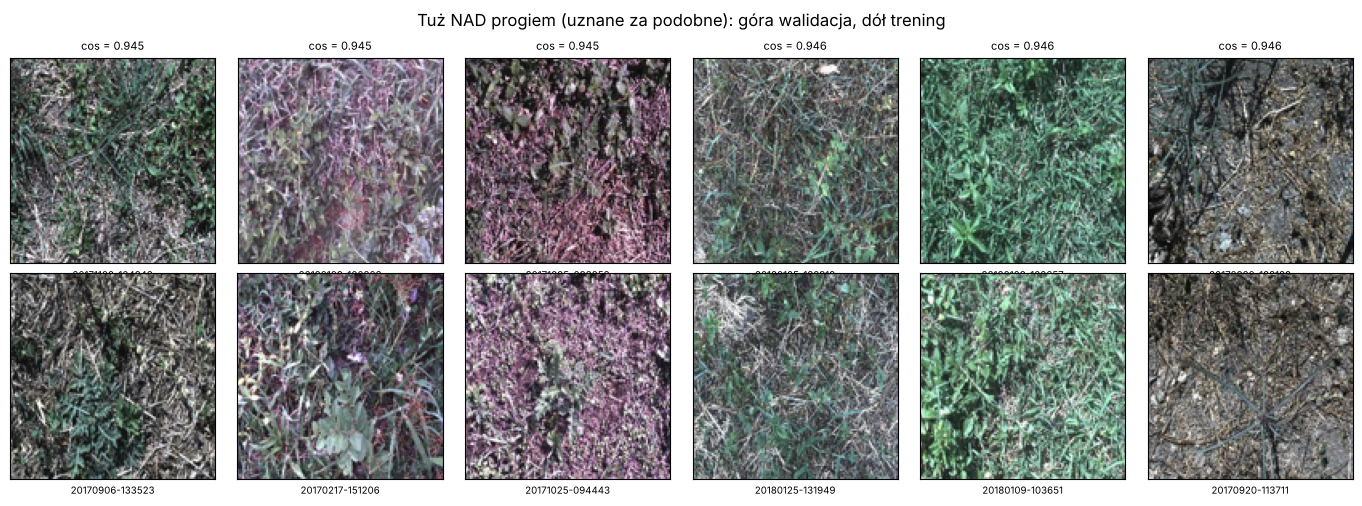

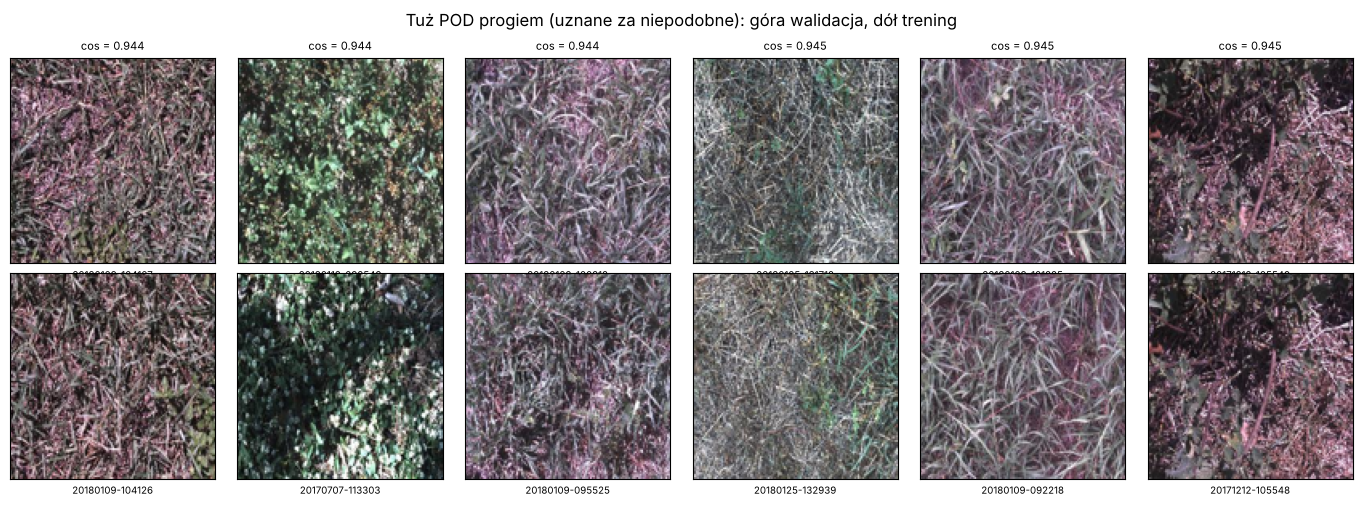

In [8]:
# B4. Ręczne sprawdzenie par: tuż nad progiem, tuż pod progiem
def miniatura(plik):
    """Zdjęcie zmniejszone do 128 x 128 (tylko do podglądu, żeby notatnik był lżejszy)."""
    return Image.open(IMG_DIR / plik).resize((128, 128))


def pokaz_pary(pary, tytul):
    fig, axes = plt.subplots(2, len(pary), figsize=(2.3 * len(pary), 5))
    for k, (plik_a, plik_b, s) in enumerate(pary):
        axes[0, k].imshow(miniatura(plik_a))
        axes[1, k].imshow(miniatura(plik_b))
        axes[0, k].set_title(f"cos = {s:.3f}", fontsize=8)
        axes[1, k].set_xlabel(plik_b[:15], fontsize=7)
        axes[0, k].set_xlabel(plik_a[:15], fontsize=7)
        for ax in axes[:, k]:
            ax.set_xticks([])
            ax.set_yticks([])
    plt.suptitle(tytul)
    plt.tight_layout()
    plt.show()


kolejnosc = np.argsort(max_val)
nad = [i for i in kolejnosc if max_val[i] >= PROG][:6]                 # 6 najsłabszych "podobnych"
pod = [i for i in kolejnosc if max_val[i] < PROG][-6:]                 # 6 najmocniejszych "niepodobnych"
pokaz_pary([(val.Filename.iloc[i], train.Filename.iloc[najblizszy[i]], max_val[i]) for i in nad],
           "Tuż NAD progiem (uznane za podobne): góra walidacja, dół trening")
pokaz_pary([(val.Filename.iloc[i], train.Filename.iloc[najblizszy[i]], max_val[i]) for i in pod],
           "Tuż POD progiem (uznane za niepodobne): góra walidacja, dół trening")

zdjęcia testowe z bliźniakiem w treningu: 123 z 3507 (3.5%)
                zdjęcia testowe  z bliźniakiem  odsetek
Chinee apple                226              0    0.000
Lantana                     213              1    0.005
Parkinsonia                 207              8    0.039
Parthenium                  205             23    0.112
Prickly acacia              213              9    0.042
Rubber vine                 202              0    0.000
Siam weed                   215              2    0.009
Snake weed                  204              1    0.005
Negative                   1822             79    0.043


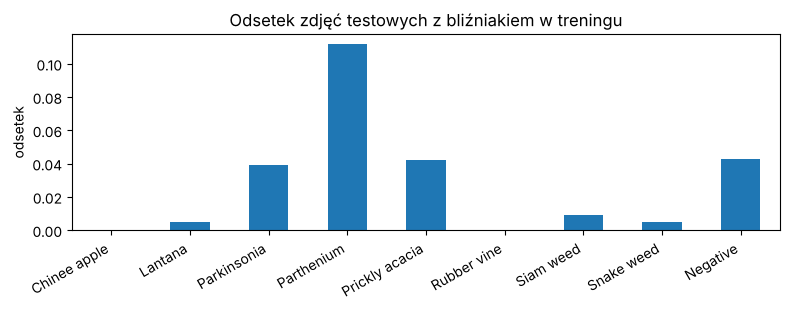

In [9]:
# B5. Ile zdjęć testowych ma bliźniaka w treningu i jak to rozkłada się na klasy
podob_test = N_test @ N_train.T                    # 3507 x 10501
max_test = podob_test.max(axis=1)
ma_blizniaka = max_test >= PROG
najblizszy_test = podob_test.argmax(axis=1)
print(f"zdjęcia testowe z bliźniakiem w treningu: {ma_blizniaka.sum()} z {len(test)} ({ma_blizniaka.mean():.1%})")

na_klase = pd.DataFrame({"zdjęcia testowe": np.bincount(y_test, minlength=9),
                         "z bliźniakiem": np.bincount(y_test[ma_blizniaka], minlength=9)}, index=KLASY)
na_klase["odsetek"] = (na_klase["z bliźniakiem"] / na_klase["zdjęcia testowe"]).round(3)
print(na_klase)
na_klase["odsetek"].plot(kind="bar", figsize=(8, 3.2), title="Odsetek zdjęć testowych z bliźniakiem w treningu")
plt.ylabel("odsetek")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [10]:
# B6. Trzy warianty zbioru treningowego
# Oczyszczony: usuwam każde zdjęcie treningowe, które jest bliźniakiem (podobieństwo >= próg)
# dowolnego zdjęcia testowego.
do_usuniecia = (podob_test >= PROG).any(axis=0)       # dla każdego zdjęcia treningowego
usuniete_na_klase = np.bincount(y_train[do_usuniecia], minlength=9)
print(f"usuwane zdjęcia treningowe: {do_usuniecia.sum()} z {len(train)} ({do_usuniecia.mean():.1%})")
print(pd.Series(usuniete_na_klase, index=KLASY, name="usunięte w wariancie oczyszczonym"))


def wariant_kontrolny(ziarno, ile_na_klase=usuniete_na_klase):
    """Usuwa losowe zdjęcia treningowe, w każdej klasie tyle samo co w wariancie oczyszczonym."""
    los = np.random.default_rng(ziarno)
    maska = np.zeros(len(train), dtype=bool)
    for klasa in range(9):
        kandydaci = np.where(y_train == klasa)[0]
        maska[los.choice(kandydaci, size=ile_na_klase[klasa], replace=False)] = True
    return ~maska                                      # True = zdjęcie zostaje


warianty = {"oryginalny": np.ones(len(train), dtype=bool), "oczyszczony": ~do_usuniecia}
ZIARNA_KONTROLNE = list(range(10))                     # 10 losowań wariantu kontrolnego
for z in ZIARNA_KONTROLNE:
    warianty[f"kontrolny_{z}"] = wariant_kontrolny(z)

usuwane zdjęcia treningowe: 161 z 10501 (1.5%)
Chinee apple       0
Lantana            1
Parkinsonia       13
Parthenium        37
Prickly acacia    12
Rubber vine        0
Siam weed          2
Snake weed         1
Negative          95
Name: usunięte w wariancie oczyszczonym, dtype: int64


In [11]:
# B7. Trening tego samego modelu na każdym wariancie i ocena na niezmienionym teście
predykcje = {}
for nazwa, zostaje in warianty.items():
    model = nowy_model()
    model.fit(X_train[zostaje], y_train[zostaje])
    predykcje[nazwa] = model.predict(X_test)
    print(f"{nazwa:13s} trening {zostaje.sum():5d} zdjęć   macro F1 test = "
          f"{f1_score(y_test, predykcje[nazwa], average='macro'):.4f}")

oryginalny    trening 10501 zdjęć   macro F1 test = 0.7064


oczyszczony   trening 10340 zdjęć   macro F1 test = 0.7046


kontrolny_0   trening 10340 zdjęć   macro F1 test = 0.7036


kontrolny_1   trening 10340 zdjęć   macro F1 test = 0.7058


kontrolny_2   trening 10340 zdjęć   macro F1 test = 0.7047


kontrolny_3   trening 10340 zdjęć   macro F1 test = 0.7039


... (2 outputs left out)

kontrolny_6   trening 10340 zdjęć   macro F1 test = 0.7054


kontrolny_7   trening 10340 zdjęć   macro F1 test = 0.7004


kontrolny_8   trening 10340 zdjęć   macro F1 test = 0.7017


kontrolny_9   trening 10340 zdjęć   macro F1 test = 0.7040


### Wnioski z części B
- **Metoda:** podobieństwo cosinusowe cech ResNet34, jak u Barza i Denzlera (2020). Działa lepiej
  niż porównywanie pikseli, bo toleruje małe przesunięcia kadru i zmiany światła między kolejnymi
  zdjęciami.
- **Próg 0,9448** ustaliłem tylko na treningu i walidacji: to 99. percentyl podobieństwa
  zdjęć walidacyjnych do najbliższego zdjęcia treningowego **z innego dnia**, czyli do zdjęcia,
  które na pewno jest innym ujęciem. Powyżej progu znalazło się 2,8% zdjęć walidacyjnych.
  Pary nad progiem w 49% pochodzą z tej samej sesji (do 10 minut odstępu), pary pod progiem
  tylko w 26%, więc próg rzeczywiście wychwytuje ujęcia z tego samego miejsca i czasu.
- **Ręczne sprawdzenie:** pary tuż nad progiem to zwykle ten sam typ roślinności i oświetlenia,
  ale nie ta sama roślina. Pary tuż pod progiem wyglądają podobnie. Prawdziwe prawie duplikaty
  (ta sama roślina, lekko przesunięty kadr) mają podobieństwo powyżej około 0,97. Próg jest więc
  **liberalny**: obejmuje prawie duplikaty i dodatkowo bardzo podobne sceny.
- **Test:** 123 z 3 507 zdjęć testowych (3,5%) ma bliźniaka w treningu, a tylko 8 ma podobieństwo
  powyżej 0,97. Rozkład jest nierówny: Parthenium 11,2%, Negative 4,3%, Prickly acacia 4,2%,
  Parkinsonia 3,9%, Chinee apple i Rubber vine 0%.
- **Warianty:** oczyszczony usuwa 161 zdjęć treningowych (1,5%), głównie Negative (95)
  i Parthenium (37). Kontrolny usuwa w każdej klasie tyle samo losowych zdjęć, w 10 losowaniach.

## C — Analiza dowodów i wniosek

Porównaj macro-F1 i wyniki klas dla trzech wariantów. Najważniejsza jest różnica między wariantem oczyszczonym i kontrolnym, ponieważ oba zawierają mniej danych. Dodaj prostą ocenę niepewności, na przykład przedział ufności albo powtórzenie eksperymentu dla kilku ziaren.

Pokaż przykłady podobnych par i reprezentatywne błędy. Sprawdź również, czy model częściej poprawnie klasyfikuje obrazy testowe mające podobny odpowiednik w treningu. Pamiętaj, że taki związek sam w sobie nie dowodzi zapamiętywania obrazów.

Zakończ odpowiedzią na pytanie badawcze i odnieś ją do ustalonego wcześniej kryterium. Wynik niepotwierdzający hipotezy jest poprawnym wynikiem. Wskaż najważniejsze ograniczenia badania, w tym fakt, że eksperyment dotyczy jednego foldu i nie zastępuje testu na danych z nowego miejsca lub czasu.

                           oryginalny  oczyszczony  kontrolny (średnia z 10)
liczba zdjęć treningowych  10501.0000   10340.0000                10340.0000
macro F1                       0.7064       0.7046                    0.7037
accuracy                       0.7779       0.7764                    0.7758
balanced accuracy              0.6696       0.6683                    0.6667

macro F1 wariantu kontrolnego w 10 losowaniach: od 0.7004 do 0.7058

F1 dla poszczególnych klas:
                oryginalny  oczyszczony  kontrolny (średnia)  oczyszczony minus kontrolny
Chinee apple        0.6422       0.6373               0.6366                       0.0006
Lantana             0.7010       0.6942               0.6994                      -0.0052
Parkinsonia         0.8460       0.8439               0.8418                       0.0021
Parthenium          0.6429       0.6446               0.6347                       0.0100
Prickly acacia      0.7677       0.7659               0.7655       

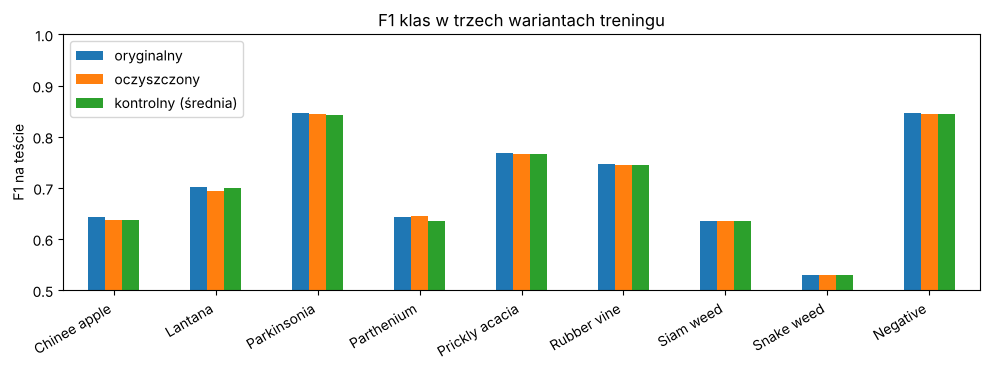

In [12]:
# C1. Tabela porównawcza trzech wariantów
def f1_klas(pred):
    return f1_score(y_test, pred, average=None)


kontrolne = [f"kontrolny_{z}" for z in ZIARNA_KONTROLNE]
f1_kontrolne = np.array([f1_score(y_test, predykcje[k], average="macro") for k in kontrolne])

tabela = pd.DataFrame({
    "oryginalny": [len(train), f1_score(y_test, predykcje["oryginalny"], average="macro"),
                   accuracy_score(y_test, predykcje["oryginalny"]),
                   balanced_accuracy_score(y_test, predykcje["oryginalny"])],
    "oczyszczony": [warianty["oczyszczony"].sum(), f1_score(y_test, predykcje["oczyszczony"], average="macro"),
                    accuracy_score(y_test, predykcje["oczyszczony"]),
                    balanced_accuracy_score(y_test, predykcje["oczyszczony"])],
    "kontrolny (średnia z 10)": [warianty["kontrolny_0"].sum(), f1_kontrolne.mean(),
                                 np.mean([accuracy_score(y_test, predykcje[k]) for k in kontrolne]),
                                 np.mean([balanced_accuracy_score(y_test, predykcje[k]) for k in kontrolne])],
}, index=["liczba zdjęć treningowych", "macro F1", "accuracy", "balanced accuracy"])
print(tabela.round(4))
print(f"\nmacro F1 wariantu kontrolnego w 10 losowaniach: od {f1_kontrolne.min():.4f} do {f1_kontrolne.max():.4f}")

klasy_tab = pd.DataFrame({
    "oryginalny": f1_klas(predykcje["oryginalny"]),
    "oczyszczony": f1_klas(predykcje["oczyszczony"]),
    "kontrolny (średnia)": np.mean([f1_klas(predykcje[k]) for k in kontrolne], axis=0),
}, index=KLASY)
klasy_tab["oczyszczony minus kontrolny"] = klasy_tab["oczyszczony"] - klasy_tab["kontrolny (średnia)"]
print("\nF1 dla poszczególnych klas:")
print(klasy_tab.round(4))

klasy_tab[["oryginalny", "oczyszczony", "kontrolny (średnia)"]].plot(kind="bar", figsize=(10, 3.8))
plt.ylabel("F1 na teście")
plt.ylim(0.5, 1.0)
plt.title("F1 klas w trzech wariantach treningu")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Δ (kontrolny minus oczyszczony) = -0.0009, 95% przedział ufności: [-0.0037, 0.0019]
oryginalny minus oczyszczony     = 0.0018, 95% przedział ufności: [-0.0012, 0.0048]
kryterium: Δ >= 0,02 i dolna granica > 0  ->  hipoteza NIEPOTWIERDZONA


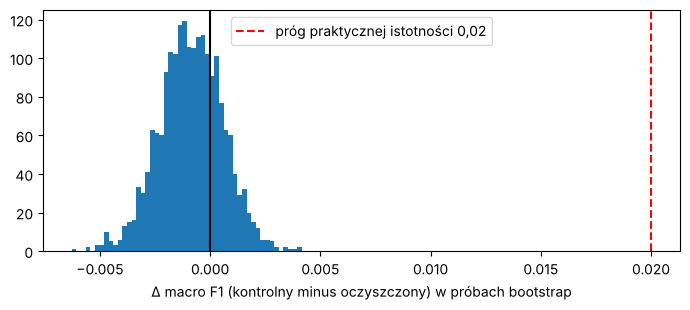

In [13]:
# C2. Niepewność: bootstrap na zbiorze testowym
# Losujemy 2000 razy (ze zwracaniem) zestaw 3507 zdjęć testowych i za każdym razem liczymy
# różnicę macro F1. Te same wylosowane zdjęcia dla obu wariantów, więc porównanie jest sparowane.
# Środkowe 95% wyników to przedział ufności.
los = np.random.default_rng(RS)
B = 2000
delta_kontrolny = np.zeros(B)      # kontrolny (średnio po 10 losowaniach) minus oczyszczony
delta_oryginalny = np.zeros(B)     # oryginalny minus oczyszczony
for b in range(B):
    i = los.integers(0, len(y_test), len(y_test))
    f1_ocz = f1_score(y_test[i], predykcje["oczyszczony"][i], average="macro")
    f1_kon = np.mean([f1_score(y_test[i], predykcje[k][i], average="macro") for k in kontrolne])
    delta_kontrolny[b] = f1_kon - f1_ocz
    delta_oryginalny[b] = f1_score(y_test[i], predykcje["oryginalny"][i], average="macro") - f1_ocz

DELTA = f1_kontrolne.mean() - f1_score(y_test, predykcje["oczyszczony"], average="macro")
przedzial = np.quantile(delta_kontrolny, [0.025, 0.975])
przedzial_or = np.quantile(delta_oryginalny, [0.025, 0.975])
delta_or = f1_score(y_test, predykcje["oryginalny"], average="macro") - f1_score(y_test, predykcje["oczyszczony"], average="macro")
print(f"Δ (kontrolny minus oczyszczony) = {DELTA:.4f}, 95% przedział ufności: [{przedzial[0]:.4f}, {przedzial[1]:.4f}]")
print(f"oryginalny minus oczyszczony     = {delta_or:.4f}, 95% przedział ufności: [{przedzial_or[0]:.4f}, {przedzial_or[1]:.4f}]")
print(f"kryterium: Δ >= 0,02 i dolna granica > 0  ->  "
      f"{'hipoteza POTWIERDZONA' if (DELTA >= 0.02 and przedzial[0] > 0) else 'hipoteza NIEPOTWIERDZONA'}")

plt.figure(figsize=(7, 3.2))
plt.hist(delta_kontrolny, bins=50)
plt.axvline(0, color="k")
plt.axvline(0.02, color="r", ls="--", label="próg praktycznej istotności 0,02")
plt.xlabel("Δ macro F1 (kontrolny minus oczyszczony) w próbach bootstrap")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# C3. Czy zdjęcia testowe z bliźniakiem są częściej klasyfikowane poprawnie?
trafne = predykcje["oryginalny"] == y_test
print(f"accuracy (model oryginalny) dla zdjęć z bliźniakiem:  {trafne[ma_blizniaka].mean():.4f} ({ma_blizniaka.sum()} zdjęć)")
print(f"accuracy (model oryginalny) dla zdjęć bez bliźniaka:  {trafne[~ma_blizniaka].mean():.4f} ({(~ma_blizniaka).sum()} zdjęć)")

# To samo w każdej klasie osobno, bo klasy mają różny odsetek bliźniaków i różną trudność.
porownanie = pd.DataFrame({
    "z bliźniakiem": [trafne[(y_test == k) & ma_blizniaka].mean() if ((y_test == k) & ma_blizniaka).any() else np.nan
                      for k in range(9)],
    "bez bliźniaka": [trafne[(y_test == k) & ~ma_blizniaka].mean() for k in range(9)],
    "liczba z bliźniakiem": [((y_test == k) & ma_blizniaka).sum() for k in range(9)],
}, index=KLASY)
print(porownanie.round(3))

# Czy bliźniak z treningu ma tę samą etykietę co zdjęcie testowe?
ta_sama = y_train[najblizszy_test[ma_blizniaka]] == y_test[ma_blizniaka]
print(f"\nbliźniak z treningu ma tę samą klasę w {ta_sama.mean():.1%} przypadków")

accuracy (model oryginalny) dla zdjęć z bliźniakiem:  0.8618 (123 zdjęć)
accuracy (model oryginalny) dla zdjęć bez bliźniaka:  0.7748 (3384 zdjęć)
                z bliźniakiem  bez bliźniaka  liczba z bliźniakiem
Chinee apple              NaN          0.580                     0
Lantana                 0.000          0.675                     1
Parkinsonia             0.875          0.834                     8
Parthenium              0.870          0.533                    23
Prickly acacia          0.667          0.740                     9
Rubber vine               NaN          0.698                     0
Siam weed               0.500          0.573                     2
Snake weed              0.000          0.458                     1
Negative                0.911          0.905                    79

bliźniak z treningu ma tę samą klasę w 85.4% przypadków


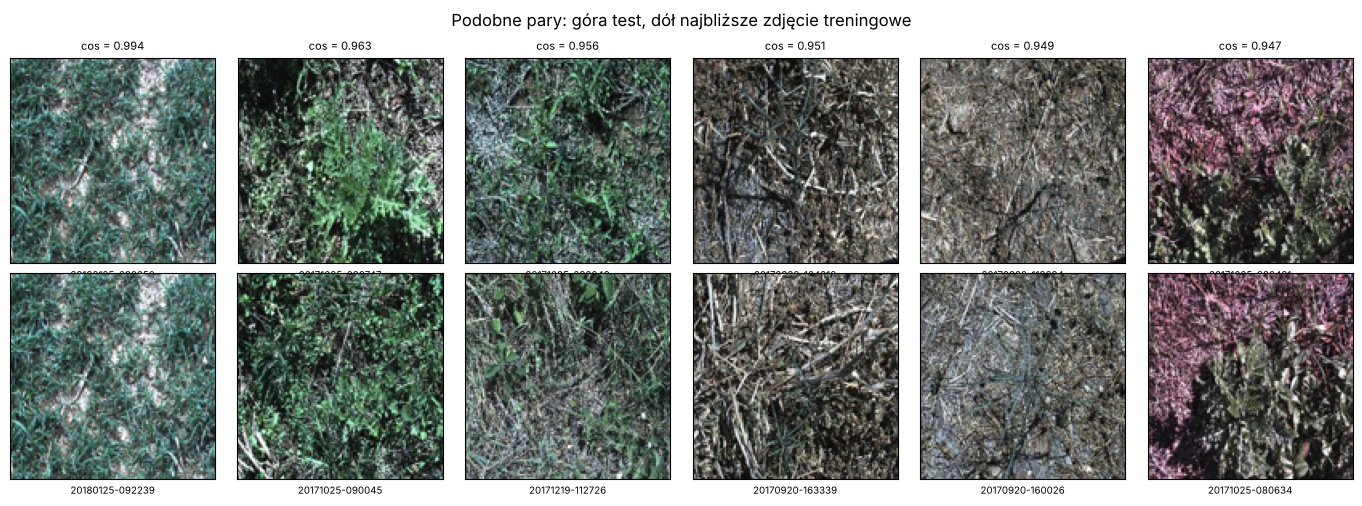

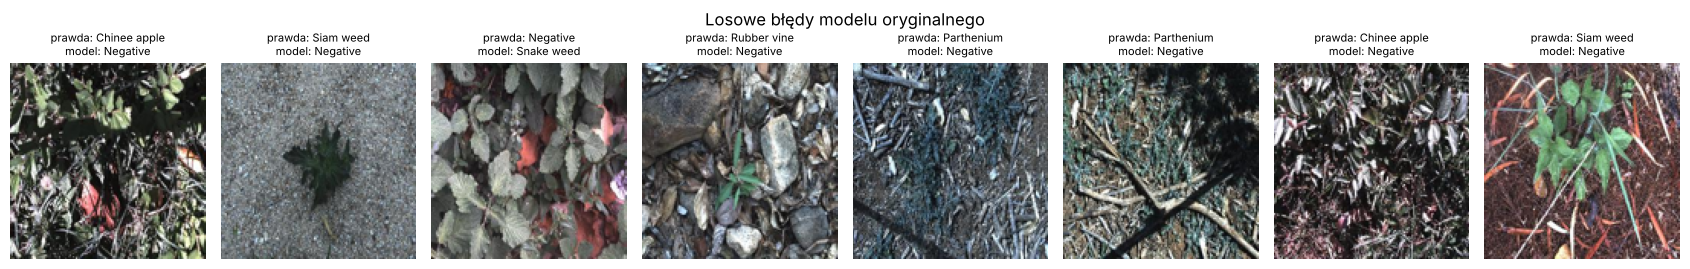

                precision    recall  f1-score   support

  Chinee apple      0.720     0.580     0.642       226
       Lantana      0.733     0.671     0.701       213
   Parkinsonia      0.856     0.836     0.846       207
    Parthenium      0.736     0.571     0.643       205
Prickly acacia      0.801     0.737     0.768       213
   Rubber vine      0.801     0.698     0.746       202
     Siam weed      0.715     0.572     0.636       215
    Snake weed      0.633     0.456     0.530       204
      Negative      0.794     0.906     0.846      1822

      accuracy                          0.778      3507
     macro avg      0.754     0.670     0.706      3507
  weighted avg      0.772     0.778     0.770      3507



In [15]:
# C4. Przykłady podobnych par i reprezentatywne błędy
przyklady = np.where(ma_blizniaka)[0]
przyklady = przyklady[np.argsort(-max_test[przyklady])][::max(1, len(przyklady) // 6)][:6]
pokaz_pary([(test.Filename.iloc[i], train.Filename.iloc[najblizszy_test[i]], max_test[i]) for i in przyklady],
           "Podobne pary: góra test, dół najbliższe zdjęcie treningowe")

bledy = np.where(~trafne)[0]
los_b = np.random.default_rng(RS)
wybrane = los_b.choice(bledy, size=8, replace=False)
fig, axes = plt.subplots(1, 8, figsize=(17, 2.8))
for ax, i in zip(axes, wybrane):
    ax.imshow(miniatura(test.Filename.iloc[i]))
    ax.set_title(f"prawda: {KLASY[y_test[i]]}\nmodel: {KLASY[predykcje['oryginalny'][i]]}", fontsize=8)
    ax.axis("off")
plt.suptitle("Losowe błędy modelu oryginalnego")
plt.tight_layout()
plt.show()
print(classification_report(y_test, predykcje["oryginalny"], target_names=KLASY, digits=3))

In [16]:
# C5. Analiza dodatkowa: czy wynik zależy od progu? (wykonana PO wyniku głównym)
# Ta analiza nie zmienia kryterium ani wniosku głównego. Sprawdza tylko, czy brak efektu
# nie wynika z wyboru jednego progu. Testuję luźniejsze i ostrzejsze progi podobieństwa oraz
# drugą, niezależną od cech definicję bliskości: zdjęcie treningowe zrobione najwyżej 10 albo 30 sekund
# od dowolnego zdjęcia testowego (ta sama sesja zbierania danych, prawie to samo miejsce).
sek_train = (czas_train - pd.Timestamp("2016-01-01")).dt.total_seconds().to_numpy()
sek_test = np.sort((czas_test - pd.Timestamp("2016-01-01")).dt.total_seconds().to_numpy())


def odstep_od_testu(sekundy):
    """Dla każdego zdjęcia treningowego: odstęp w sekundach do najbliższego w czasie zdjęcia testowego."""
    pozycja = np.searchsorted(sek_test, sekundy)
    przed = sek_test[np.clip(pozycja - 1, 0, len(sek_test) - 1)]
    po = sek_test[np.clip(pozycja, 0, len(sek_test) - 1)]
    return np.minimum(np.abs(sekundy - przed), np.abs(po - sekundy))


odstep_train = odstep_od_testu(sek_train)
print(f"zdjęcia treningowe zrobione do 10 s od jakiegoś zdjęcia testowego: {np.mean(odstep_train <= 10):.1%}")


def porownaj(usun, opis, ziarna=range(5)):
    """Ten sam eksperyment co w B6 i B7 dla innej definicji bliźniaka (5 losowań kontrolnych)."""
    ile = np.bincount(y_train[usun], minlength=9)
    f1_ocz = f1_score(y_test, nowy_model().fit(X_train[~usun], y_train[~usun]).predict(X_test), average="macro")
    f1_kon = []
    for z in ziarna:
        zostaje = wariant_kontrolny(100 + z, ile)
        f1_kon.append(f1_score(y_test, nowy_model().fit(X_train[zostaje], y_train[zostaje]).predict(X_test),
                               average="macro"))
    return {"definicja bliźniaka": opis, "usunięte zdjęcia": int(usun.sum()),
            "macro F1 oczyszczony": f1_ocz, "macro F1 kontrolny (średnia z 5)": np.mean(f1_kon),
            "Δ (kontrolny minus oczyszczony)": np.mean(f1_kon) - f1_ocz}


czulosc = [porownaj((podob_test >= p).any(axis=0), f"cosinus >= {p:.4f}" + (" (główny)" if p == PROG else ""))
           for p in [0.90, 0.92, 0.93, PROG, 0.96]]
czulosc += [porownaj(odstep_train <= s, f"zrobione do {s} s od zdjęcia testowego") for s in [10, 30]]
czulosc = pd.DataFrame(czulosc)
print(czulosc.round(4).to_string(index=False))

zdjęcia treningowe zrobione do 10 s od jakiegoś zdjęcia testowego: 22.6%


                  definicja bliźniaka  usunięte zdjęcia  macro F1 oczyszczony  macro F1 kontrolny (średnia z 5)  Δ (kontrolny minus oczyszczony)
                    cosinus >= 0.9000              2450                0.6876                            0.6921                           0.0045
                    cosinus >= 0.9200              1095                0.6966                            0.7003                           0.0037
                    cosinus >= 0.9300               589                0.7021                            0.7014                          -0.0006
           cosinus >= 0.9448 (główny)               161                0.7046                            0.7031                          -0.0015
                    cosinus >= 0.9600                24                0.7064                            0.7060                          -0.0004
zrobione do 10 s od zdjęcia testowego              2375                0.6995                            0.7016                   

### Wnioski
**Wyniki (macro F1 na tym samym teście):**

| wariant | zdjęcia treningowe | macro F1 | accuracy |
|---|---|---|---|
| oryginalny | 10 501 | 0,7064 | 0,7779 |
| oczyszczony | 10 340 | 0,7046 | 0,7764 |
| kontrolny (średnia z 10 losowań) | 10 340 | 0,7037 (od 0,7004 do 0,7058) | 0,7758 |

- **Δ = kontrolny minus oczyszczony = −0,0009**, 95% przedział ufności (bootstrap) od −0,0037
  do 0,0019. Δ jest daleko poniżej ustalonego progu 0,02, a przedział obejmuje zero.
  **Hipoteza nie została potwierdzona.** Wariant oczyszczony nie jest gorszy od kontrolnego.
  Nawet różnica oryginalny minus oczyszczony (0,0018, przedział od −0,0012 do 0,0048)
  jest nieistotna.
- **Klasy:** największa zmiana jest w Parthenium, klasie z największą liczbą bliźniaków, ale ma
  znak przeciwny do hipotezy (oczyszczony 0,645, kontrolny 0,635). W pozostałych klasach różnice
  są poniżej 0,006.
- **Zdjęcia z bliźniakiem** model oryginalny klasyfikuje poprawnie częściej (86,2%) niż pozostałe
  (77,5%). To jednak głównie efekt składu: w klasie Negative różnica prawie znika (91,1% i 90,5%),
  a duża różnica w Parthenium (87% i 53%) dotyczy tylko 23 zdjęć. Taki związek nie dowodzi
  zapamiętywania: zdjęcia z bliźniakiem mogą być po prostu typowymi, łatwymi scenami.
  Eksperyment pokazuje, że usunięcie bliźniaków z treningu nie pogarsza wyniku, więc trafność
  na tych zdjęciach nie wynika z zapamiętania konkretnego zdjęcia treningowego.
- **Analiza dodatkowa (po wyniku głównym):** przy progach od 0,90 do 0,96 Δ mieści się między
  −0,0015 a 0,0045. Dopiero usunięcie wszystkich zdjęć treningowych zrobionych do 30 sekund od
  zdjęcia testowego (59% treningu) daje Δ = 0,0185, nadal poniżej 0,02 i bez oceny niepewności.
  Może to wskazywać na słabą zależność między zdjęciami z tej samej sesji (to samo miejsce
  i warunki), ale nie na zawyżanie wyniku przez prawie identyczne ujęcia.

**Odpowiedź na pytanie badawcze:** na foldzie 0 wynik użytego modelu nie jest zauważalnie zawyżony
przez bardzo podobne ujęcia w treningu i teście. Takich zdjęć jest mało (3,5% przy liberalnym
progu, około 0,2% prawdziwych prawie duplikatów), a ich usunięcie obniża wynik nie bardziej niż
usunięcie tej samej liczby losowych zdjęć. Według kryterium ustalonego przed eksperymentem
hipoteza nie została potwierdzona.

**Ograniczenia:**
1. Jeden fold. Inne foldy mogą mieć inny odsetek bliźniaków.
2. Jeden typ modelu: zamrożone cechy i model liniowy zapamiętują pojedyncze zdjęcia słabiej niż
   sieć douczana na tych danych albo klasyfikator najbliższego sąsiada. Dla takich modeli efekt
   może być większy. Mój model (macro F1 0,706) jest też dużo słabszy niż ResNet50 z publikacji
   (accuracy 95,7%).
3. Podobieństwo liczę w tej samej przestrzeni cech, której używa klasyfikator, a próg zależy
   od przyjętej definicji (99. percentyl).
4. Bootstrap traktuje zdjęcia testowe jako niezależne, a zdjęcia z jednej sesji są skorelowane,
   więc przedziały ufności są raczej zbyt wąskie.
5. Badanie dotyczy podziału losowego w obrębie tych samych miejsc i dni. Nie zastępuje testu
   na zdjęciach z nowego miejsca lub z innego okresu, który najlepiej sprawdziłby uogólnianie.

## Oddanie zadania

Zapisz w notatniku hipotezę, kod, wyniki, wykresy i wnioski. Dodaj krótką tabelę porównującą trzy warianty oraz opisz ograniczenia badania. Podaj wykorzystane źródła. Opublikuj kod w repozytorium.

**Źródła:**
- A. Olsen i in., "DeepWeeds: A Multiclass Weed Species Image Dataset for Deep Learning",
  Scientific Reports 9, 2058 (2019), https://doi.org/10.1038/s41598-018-38343-3
- B. Barz, J. Denzler, "Do We Train on Test Data? Purging CIFAR of Near-Duplicates",
  Journal of Imaging 6(6), 41 (2020), https://arxiv.org/abs/1902.00423
- K. He i in., "Deep Residual Learning for Image Recognition", CVPR 2016 (architektura ResNet);
  wagi ImageNet z biblioteki timm (R. Wightman), plik resnet34-43635321.pth.
- B. Efron, R. Tibshirani, "An Introduction to the Bootstrap", 1993 (przedziały ufności bootstrap).
- dokumentacja modelu bazowego (README w repozytorium AI-MED-AGH/Recruitment-Task-3-Model),
  dokumentacja PyTorch, torchvision i scikit-learn.

**Narzędzia AI:** Claude (Anthropic), pomoc przy pisaniu kodu i wyjaśnianiu bibliotek.